# 04. 생산 이력 전체 보기

**어느 기계로, 언제, 무엇을 만들었고, 그중 어디에 검사 결과가 붙어 있는가.**

라벨 파일과 비라벨 파일을 합쳐서 하나의 달력으로 만듭니다.
위에서부터 순서대로 실행하세요. 비라벨 파일이 커서 3번 셀이 1~2분 걸립니다.

## 0. 준비

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from src.load import RAW
from src.plotting import setup, save
setup()

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)
print("RAW =", RAW)
for p in sorted(RAW.glob("*.csv")):
    print(f"  {p.name:32s} {p.stat().st_size/1e6:8.1f} MB")

폰트: Malgun Gothic
RAW = C:\user\KAMP-Research\KAMP 2026\JIWOO\data\raw
  labeled_data.csv                      4.6 MB
  moldset_labeled.csv                   1.5 MB
  moldset_labeled_cn7.csv               0.6 MB
  moldset_labeled_rg3.csv               0.6 MB
  moldset_unlabeled_cn7.csv            16.6 MB
  moldset_unlabeled_rg3.csv            17.0 MB
  supervised_label_cn7.csv              1.8 MB
  unlabeled_data.csv                  225.6 MB


## 1. 두 파일 합치기

비라벨 파일은 필요한 컬럼만 읽습니다. 전부 읽으면 메모리를 많이 씁니다.

`PART_FACT_PLAN_DATE` 는 `2020-03-17 오전 12:00:00` 형태라 앞의 날짜만 떼어냅니다.
이 값이 **공장이 인정하는 생산일**입니다. 자정을 넘겨 도는 야간조가 하나로 묶입니다.

In [2]:
WANT = ["TimeStamp", "PART_NAME", "PART_NO", "EQUIP_NAME",
        "ERR_FACT_QTY", "PART_FACT_PLAN_DATE", "PassOrFail"]

def _read(fname, tag):
    head = pd.read_csv(RAW / fname, nrows=1)
    use = [x for x in WANT if x in head.columns]
    print(f"{fname}: {len(use)}/{len(WANT)} 컬럼 사용 — 없는 것 {set(WANT)-set(use)}")
    d = pd.read_csv(RAW / fname, usecols=use)
    d["src"] = tag
    for x in WANT:
        if x not in d.columns:
            d[x] = pd.NA
    return d

a = pd.concat([_read("unlabeled_data.csv", "비라벨"),
               _read("labeled_data.csv",   "라벨")], ignore_index=True)

a["prod"] = a["PART_NAME"].str.extract(r"^(\w+)")[0]
a["side"] = a["PART_NAME"].str.extract(r"(LH|RH)")[0]
a["ts"]   = pd.to_datetime(a["TimeStamp"], errors="coerce")
a["plan"] = pd.to_datetime(a["PART_FACT_PLAN_DATE"].astype(str)
                            .str.split().str[0], errors="coerce")
a["plan"] = a["plan"].fillna(a["ts"].dt.normalize())   # 계획일이 없으면 실제일로
a["EQ"]   = a["EQUIP_NAME"].fillna("(설비미기재)")
a["bad"]  = (a["PassOrFail"] == "N")
a["is_lab"] = (a["src"] == "라벨")

a = a[a["prod"].isin(["CN7", "RG3"])].reset_index(drop=True)
print(f"\n합계 {len(a):,}행  (라벨 {a['is_lab'].sum():,} / 비라벨 {(~a['is_lab']).sum():,})")
print(f"기간 {a['plan'].min().date()} ~ {a['plan'].max().date()}, "
      f"생산일 {a['plan'].nunique()}일")

unlabeled_data.csv: 6/7 컬럼 사용 — 없는 것 {'PassOrFail'}
labeled_data.csv: 5/7 컬럼 사용 — 없는 것 {'ERR_FACT_QTY', 'PART_NO'}

합계 133,023행  (라벨 7,992 / 비라벨 125,031)
기간 2020-03-17 ~ 2020-11-06, 생산일 117일


## 2. 설비별 총괄 — 어떤 기계가 언제 얼마나 돌았나

In [3]:
t1 = (a.groupby("EQ")
        .agg(첫날=("plan", "min"), 끝날=("plan", "max"),
             생산일=("plan", "nunique"), 행=("plan", "size"),
             라벨행=("is_lab", "sum"), 불량=("bad", "sum")))
t1["첫날"] = t1["첫날"].dt.date
t1["끝날"] = t1["끝날"].dt.date
t1["라벨비율%"] = (t1["라벨행"] / t1["행"] * 100).round(1)
print(t1.to_string())

                       첫날          끝날  생산일      행   라벨행  불량  라벨비율%
EQ                                                                
550TON-도시바     2020-03-17  2020-07-21   21  18844     0   0    0.0
650톤-우진2호기     2020-03-24  2020-11-06   91  79172  7992  71   10.1
850TON-LS 1호기  2020-03-27  2020-09-17   17  14391     0   0    0.0
수직사출기          2020-04-13  2020-10-15   29  20616     0   0    0.0


## 3. 설비 × 제품 — 어느 기계가 무엇을 만드나

한 기계에서 CN7·RG3를 **둘 다** 만들면 금형을 갈아 끼운다는 뜻입니다.
한 제품만 나오면 전용기입니다.

In [4]:
t2 = (a.groupby(["EQ", "prod", "src"]).size()
        .unstack("src", fill_value=0))
t2["합계"] = t2.sum(axis=1)
print(t2.to_string())

print("\n── 라벨 데이터는 어느 설비인가 ──")
lab = a[a["is_lab"]]
print(pd.crosstab(lab["EQ"], lab["prod"], margins=True, margins_name="계").to_string())

src                   라벨    비라벨     합계
EQ            prod                    
550TON-도시바    CN7      0  17308  17308
              RG3      0   1536   1536
650톤-우진2호기    CN7   6736  35239  41975
              RG3   1256  35941  37197
850TON-LS 1호기 RG3      0  14391  14391
수직사출기         RG3      0  20616  20616

── 라벨 데이터는 어느 설비인가 ──
prod         CN7   RG3     계
EQ                          
650톤-우진2호기  6736  1256  7992
계           6736  1256  7992


## 4. 검사율 — 어디가 기록되었고 어디가 안 되었나

**이 표가 핵심입니다.** `검사율%` 을 보세요.

- **100%** — 그날 그 설비의 모든 쇼트에 정답이 있음. 불량 수가 진짜 숫자
- **100% 미만** — 일부만 검사. 그날 불량 수는 **과소집계**. 다른 날과 비교하면 안 됨
- **표에 없는 날** — 검사 기록 전무

In [5]:
g = (a.groupby(["plan", "EQ", "prod", "src"]).size()
       .unstack("src", fill_value=0))
for col in ["라벨", "비라벨"]:
    if col not in g.columns:
        g[col] = 0
g["불량"]     = a.groupby(["plan", "EQ", "prod"])["bad"].sum()
g["검사율%"]  = (g["라벨"] / (g["라벨"] + g["비라벨"]) * 100).round(1)

lab_days = g[g["라벨"] > 0].copy()
print(f"검사 기록이 있는 (날짜·설비·제품) 조합: {len(lab_days)}개")
print(f"그중 전수 검사(100%): {(lab_days['검사율%'] == 100).sum()}개\n")
print(lab_days.to_string())

검사 기록이 있는 (날짜·설비·제품) 조합: 12개
그중 전수 검사(100%): 7개

src                           라벨   비라벨  불량   검사율%
plan       EQ         prod                       
2020-10-16 650톤-우진2호기 CN7    375  2375  17   13.6
2020-10-20 650톤-우진2호기 CN7    836   835   0   50.0
2020-10-21 650톤-우진2호기 RG3     82  2765   0    2.9
2020-10-22 650톤-우진2호기 RG3    600  2772  15   17.8
2020-10-23 650톤-우진2호기 RG3    500   266  10   65.3
2020-10-27 650톤-우진2호기 CN7   1255     0  20  100.0
2020-10-29 650톤-우진2호기 CN7    776     0   0  100.0
2020-10-30 650톤-우진2호기 CN7   1642     0   0  100.0
2020-11-03 650톤-우진2호기 CN7   1852     0   2  100.0
2020-11-04 650톤-우진2호기 RG3     71     0   7  100.0
2020-11-05 650톤-우진2호기 RG3      2     0   0  100.0
2020-11-06 650톤-우진2호기 RG3      1     0   0  100.0


In [6]:
# 전수 검사 구간만 — 날짜별 불량 비교가 유효한 유일한 구간
full = lab_days[lab_days["검사율%"] == 100]
print("── 전수 검사 구간 ──")
print(full.to_string())
print(f"\n전수 구간 불량 합계: {int(full['불량'].sum())}건")

── 전수 검사 구간 ──
src                           라벨  비라벨  불량   검사율%
plan       EQ         prod                      
2020-10-27 650톤-우진2호기 CN7   1255    0  20  100.0
2020-10-29 650톤-우진2호기 CN7    776    0   0  100.0
2020-10-30 650톤-우진2호기 CN7   1642    0   0  100.0
2020-11-03 650톤-우진2호기 CN7   1852    0   2  100.0
2020-11-04 650톤-우진2호기 RG3     71    0   7  100.0
2020-11-05 650톤-우진2호기 RG3      2    0   0  100.0
2020-11-06 650톤-우진2호기 RG3      1    0   0  100.0

전수 구간 불량 합계: 29건


## 5. 타임라인 그림

- 세로 막대 = 그날 생산 (파랑 CN7 / 주황 RG3)
- ○ = 검사한 날
- × = 불량이 나온 날

색이 바뀌는 지점이 **금형 교체**입니다. × 가 거기 붙어 있는지 보세요.

In [7]:
def timeline(a, eq_filter=None, figsize=None):
    d = a if eq_filter is None else a[a["EQ"] == eq_filter]
    g = (d.groupby(["EQ", "plan", "prod"])
           .agg(행=("plan", "size"), 라벨=("is_lab", "sum"), 불량=("bad", "sum"))
           .reset_index())
    eqs = sorted(g["EQ"].unique())
    ypos = {e: i for i, e in enumerate(eqs)}
    color = {"CN7": "#2c7fb8", "RG3": "#e67e22"}

    fig, ax = plt.subplots(figsize=figsize or (16, 1.3 * len(eqs) + 2.2))
    for _, r in g.iterrows():
        y = ypos[r["EQ"]] + (0.16 if r["prod"] == "CN7" else -0.16)
        ax.scatter(r["plan"], y, c=color[r["prod"]], alpha=.6,
                   marker="|", s=10, linewidths=5)
        if r["라벨"] > 0:
            ax.scatter(r["plan"], y, s=120, facecolors="none",
                       edgecolors="black", linewidths=1.4, zorder=3)
        if r["불량"] > 0:
            ax.scatter(r["plan"], y, s=45, c="crimson", marker="x",
                       zorder=4, linewidths=2.2)

    ax.set_yticks(range(len(eqs))); ax.set_yticklabels(eqs, fontsize=10)
    ax.set_ylim(-0.75, len(eqs) - 0.25)
    ax.grid(axis="x", alpha=.3)
    ax.set_title("생산 이력  —  막대=생산일,  ○=검사한 날,  ×=불량 발생", fontsize=12)
    ax.legend(handles=[
        Line2D([], [], color=color["CN7"], lw=6, label="CN7"),
        Line2D([], [], color=color["RG3"], lw=6, label="RG3"),
        Line2D([], [], marker="o", mfc="none", mec="k", ls="", label="검사(라벨)"),
        Line2D([], [], marker="x", color="crimson", ls="", label="불량")],
        loc="upper left", ncol=4, fontsize=9)
    plt.tight_layout()
    return fig

fig = timeline(a)
save(fig, "생산이력_전체")
plt.show()

저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\생산이력_전체.png


<Figure size 1760x814 with 1 Axes>

라벨 설비: 650톤-우진2호기
저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\생산이력_650톤-우진2호기.png


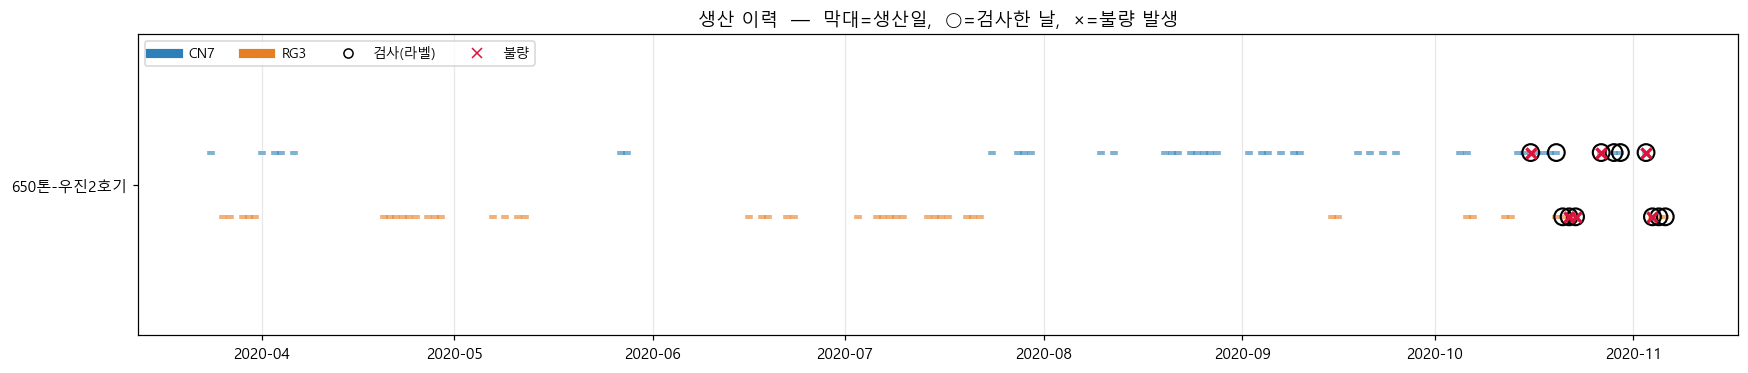

In [8]:
# 라벨이 붙은 설비만 확대
EQ_LAB = lab["EQ"].mode()[0]
print("라벨 설비:", EQ_LAB)
fig = timeline(a, eq_filter=EQ_LAB, figsize=(16, 3.5))
save(fig, f"생산이력_{EQ_LAB}")
plt.show()

## 6. 금형 교체 시점 찾기

라벨이 붙은 설비만 놓고, 생산일 순서대로 **제품이 바뀌는 지점**을 찾습니다.
그게 금형을 갈아 끼운 날입니다.

In [9]:
d = a[a["EQ"] == EQ_LAB]
seq = (d.groupby(["plan", "prod"])
         .agg(행=("plan", "size"), 라벨=("is_lab", "sum"), 불량=("bad", "sum"))
         .reset_index().sort_values("plan"))

# 같은 날 두 제품이 다 있으면 그날 교체한 것 → 행이 많은 쪽을 그날의 주제품으로
main = (seq.sort_values("행", ascending=False)
           .drop_duplicates("plan").sort_values("plan").reset_index(drop=True))
main["직전제품"] = main["prod"].shift()
main["전환"]     = main["prod"] != main["직전제품"]
main["공백일"]   = main["plan"].diff().dt.days

print(f"{EQ_LAB} : 생산일 {len(main)}일, 제품 전환 {int(main['전환'].sum())}회\n")
print(main[main["라벨"] > 0].to_string(index=False))

650톤-우진2호기 : 생산일 91일, 제품 전환 14회

      plan prod    행   라벨  불량 직전제품    전환  공백일
2020-10-16  CN7 2750  375  17  CN7 False  1.0
2020-10-20  CN7 1671  836   0  CN7 False  1.0
2020-10-21  RG3 2847   82   0  CN7  True  1.0
2020-10-22  RG3 3372  600  15  RG3 False  1.0
2020-10-23  RG3  766  500  10  RG3 False  1.0
2020-10-27  CN7 1255 1255  20  RG3  True  4.0
2020-10-29  CN7  776  776   0  CN7 False  2.0
2020-10-30  CN7 1642 1642   0  CN7 False  1.0
2020-11-03  CN7 1852 1852   2  CN7 False  4.0
2020-11-04  RG3   71   71   7  CN7  True  1.0
2020-11-05  RG3    2    2   0  RG3 False  1.0
2020-11-06  RG3    1    1   0  RG3 False  1.0


In [10]:
# 전수 검사 구간에서 '전환 직후'와 그 외를 비교
m = main.merge(
        lab_days.reset_index()[["plan", "prod", "검사율%"]],
        on=["plan", "prod"], how="left")
f = m[m["검사율%"] == 100]

if len(f):
    print("── 전수 검사한 날만 ──")
    print(f[["plan", "prod", "직전제품", "전환", "공백일", "행", "불량"]]
          .to_string(index=False))
    s = f.groupby("전환")["불량"].agg(["size", "sum"])
    s.index = ["같은 제품 이어서", "제품 전환 직후"]
    s.columns = ["날짜 수", "불량 건수"]
    print("\n" + s.to_string())
else:
    print("전수 검사 구간이 비어 있습니다. 4번 셀의 검사율 계산을 확인하세요.")

── 전수 검사한 날만 ──
      plan prod 직전제품    전환  공백일    행  불량
2020-10-27  CN7  RG3  True  4.0 1255  20
2020-10-29  CN7  CN7 False  2.0  776   0
2020-10-30  CN7  CN7 False  1.0 1642   0
2020-11-03  CN7  CN7 False  4.0 1852   2
2020-11-04  RG3  CN7  True  1.0   71   7
2020-11-05  RG3  RG3 False  1.0    2   0
2020-11-06  RG3  RG3 False  1.0    1   0

           날짜 수  불량 건수
같은 제품 이어서     5      2
제품 전환 직후      2     27


폰트: Malgun Gothic
저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\검사구간.png


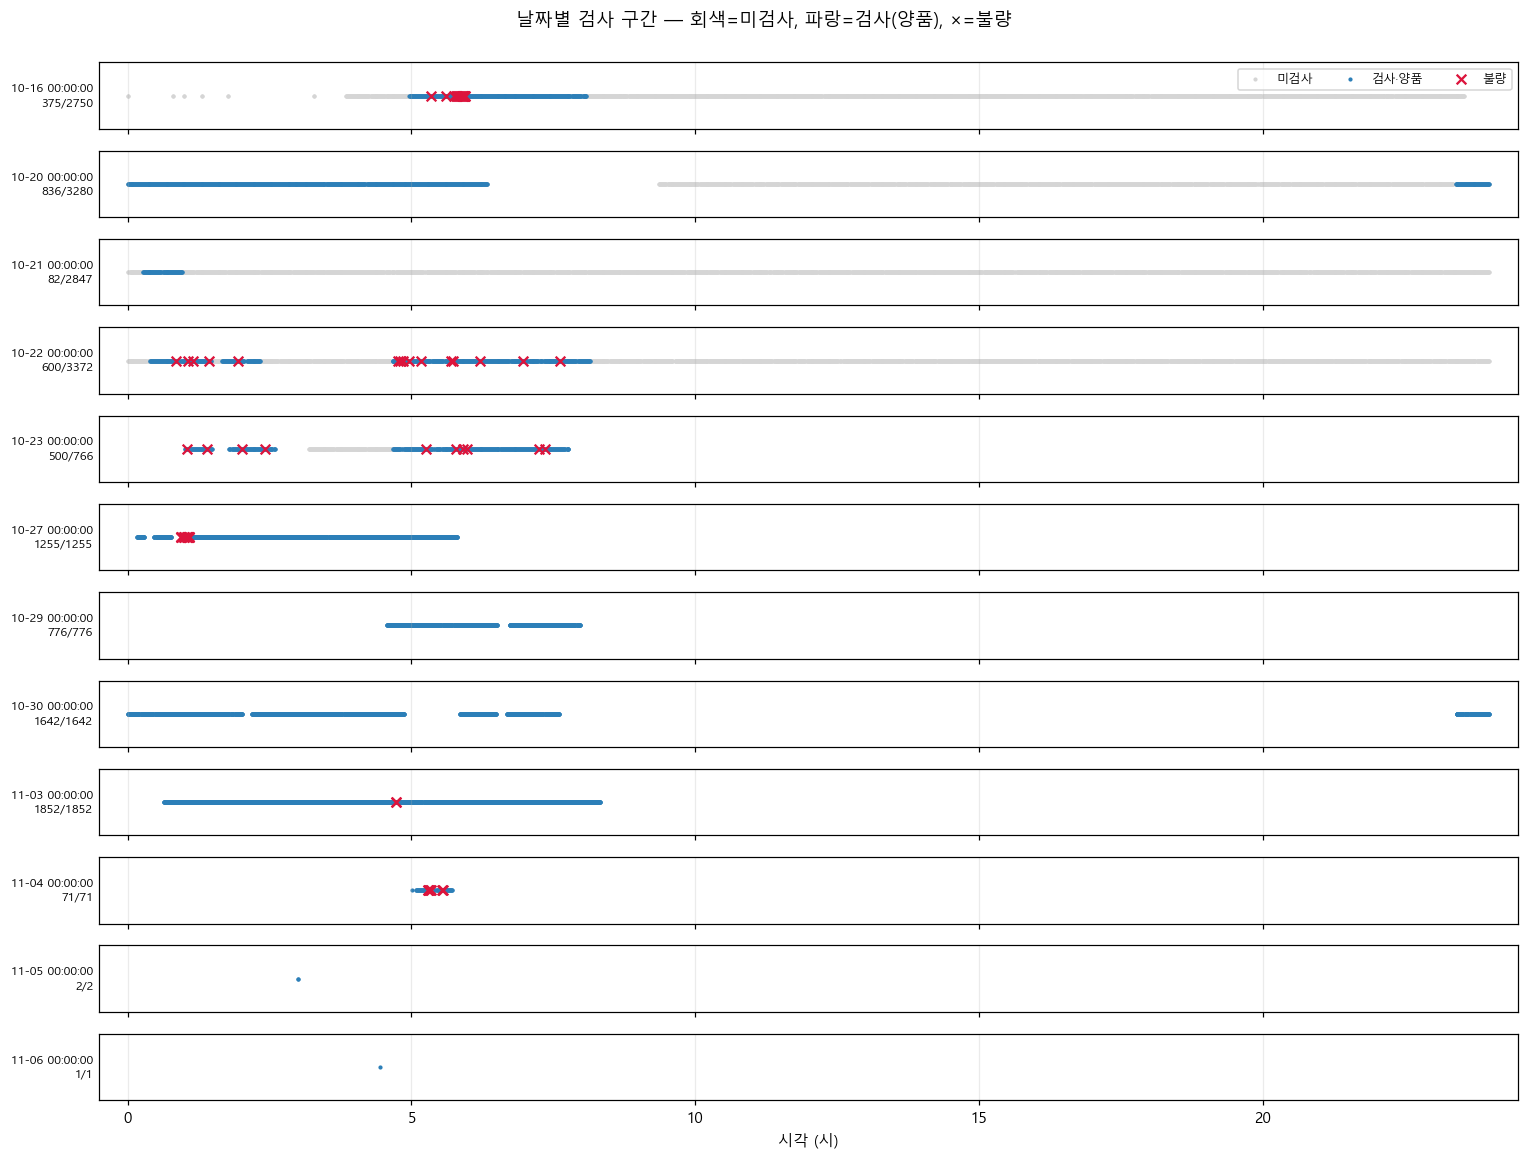

In [12]:
import matplotlib.pyplot as plt
from src.plotting import setup, save
setup()

a2 = a[a["EQ"] == "650톤-우진2호기"].copy()
a2["hour"] = a2["ts"].dt.hour + a2["ts"].dt.minute / 60
days = sorted(a2.loc[a2["is_lab"], "plan"].unique())

fig, axes = plt.subplots(len(days), 1, figsize=(14, 0.75 * len(days) + 1.5),
                         sharex=True)
for ax, d in zip(axes, days):
    s = a2[a2["plan"] == d]
    un, lb, bd = s[~s["is_lab"]], s[s["is_lab"] & ~s["bad"]], s[s["bad"]]
    ax.scatter(un["hour"], [0] * len(un), s=3, c="#d5d5d5", label="미검사")
    ax.scatter(lb["hour"], [0] * len(lb), s=3, c="#2c7fb8", label="검사·양품")
    ax.scatter(bd["hour"], [0] * len(bd), s=40, c="crimson", marker="x",
               zorder=3, label="불량")
    ax.set_yticks([])
    ax.set_ylabel(f"{str(d)[5:]}\n{len(lb)+len(bd)}/{len(s)}",
                  rotation=0, ha="right", va="center", fontsize=8)
    ax.set_xlim(-0.5, 24.5); ax.grid(axis="x", alpha=.25)
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("시각 (시)")
fig.suptitle("날짜별 검사 구간 — 회색=미검사, 파랑=검사(양품), ×=불량", y=1.0)
plt.tight_layout()
save(fig, "검사구간")
plt.show()

In [13]:
KEY = ["TimeStamp", "PART_NAME", "EQUIP_NAME", "PART_FACT_PLAN_DATE"]

# 라벨/비라벨 각각 안에서만 중복 제거 (서로 섞어서 지우면 안 됨)
ad = a.drop_duplicates(subset=["src"] + KEY, keep="first")
print(f"원본 {len(a):,}행 → 중복제거 {len(ad):,}행  (제거 {len(a)-len(ad):,})")
print(f"  라벨   {a['is_lab'].sum():,} → {ad['is_lab'].sum():,}")
print(f"  비라벨 {(~a['is_lab']).sum():,} → {(~ad['is_lab']).sum():,}")
print(f"  불량   {a['bad'].sum():.0f} → {ad['bad'].sum():.0f}")

g = (ad.groupby(["plan", "EQ", "prod", "src"]).size().unstack("src", fill_value=0))
for c in ["라벨", "비라벨"]:
    if c not in g.columns: g[c] = 0
g["불량"]    = ad.groupby(["plan", "EQ", "prod"])["bad"].sum()
g["검사율%"] = (g["라벨"] / (g["라벨"] + g["비라벨"]) * 100).round(1)

lab_days = g[g["라벨"] > 0]
print(f"\n검사 기록 조합 {len(lab_days)}개 / 전수 {(lab_days['검사율%']==100).sum()}개\n")
print(lab_days.to_string())

원본 133,023행 → 중복제거 130,195행  (제거 2,828)
  라벨   7,992 → 5,230
  비라벨 125,031 → 124,965
  불량   71 → 60

검사 기록 조합 12개 / 전수 7개

src                          라벨   비라벨  불량   검사율%
plan       EQ         prod                      
2020-10-16 650톤-우진2호기 CN7   375  2375  17   13.6
2020-10-20 650톤-우진2호기 CN7   836   835   0   50.0
2020-10-21 650톤-우진2호기 RG3    82  2765   0    2.9
2020-10-22 650톤-우진2호기 RG3   600  2772  15   17.8
2020-10-23 650톤-우진2호기 RG3   500   266  10   65.3
2020-10-27 650톤-우진2호기 CN7   628     0  10  100.0
2020-10-29 650톤-우진2호기 CN7   388     0   0  100.0
2020-10-30 650톤-우진2호기 CN7   821     0   0  100.0
2020-11-03 650톤-우진2호기 CN7   926     0   1  100.0
2020-11-04 650톤-우진2호기 RG3    71     0   7  100.0
2020-11-05 650톤-우진2호기 RG3     2     0   0  100.0
2020-11-06 650톤-우진2호기 RG3     1     0   0  100.0


In [14]:
d = ad[ad["EQ"] == "650톤-우진2호기"]
print(f"전체   {len(d):,}행  (원본 79,172)")
print(f"라벨   {d['is_lab'].sum():,}행  (원본 7,992)")
print(f"비라벨 {(~d['is_lab']).sum():,}행  (원본 71,180)")
print(f"라벨비율 {d['is_lab'].mean()*100:.1f}%  (원본 10.1%)")
print(f"불량   {d['bad'].sum():.0f}건  (원본 71)")

전체   76,370행  (원본 79,172)
라벨   5,230행  (원본 7,992)
비라벨 71,140행  (원본 71,180)
라벨비율 6.8%  (원본 10.1%)
불량   60건  (원본 71)


## 7. 정리

아래를 채워서 회의에 가져가세요.

| 항목 | 값 |
|---|---|
| 전체 생산일 | |
| 설비 수 | |
| 라벨이 붙은 설비 | |
| 검사 기록이 있는 날 | |
| 그중 전수 검사한 날 | |
| 제품 전환 횟수(라벨 설비) | |
| 전수 구간에서 — 전환 직후 날의 불량 | |
| 전수 구간에서 — 그 외 날의 불량 | |

마지막 두 줄의 대비가 이 노트북의 결론입니다.